<div dir="rtl">

# نوت‌بوک ۲: ممیزی کیفیت داده

**فاز ۱، تسک ۵**

سند برای ممیزی کیفیت پنج چیز می‌خواهد و برای هر کدام یک **تصمیم اولیه با دلیل**:

۱. مقادیر گمشده
۲. رکوردهای تکراری
۳. مقادیر ناممکن
۴. ناسازگاری نوع داده
۵. نمونه‌های پرت

این نوت‌بوک **چیزی پاک نمی‌کند**؛ فقط مشکلات را می‌شمارد و تصمیم را ثبت می‌کند. اجرای تصمیم‌ها (پاک‌سازی واقعی) در فاز ۲ انجام می‌شود. جدول نهایی تصمیم‌ها در `reports/phase1/quality_decisions.csv` ذخیره می‌شود.

</div>

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
PROC = ROOT / cfg["data"]["processed_dir"]
FIG = ROOT / "figures"
REP = ROOT / "reports" / "phase1"

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

reviews = pd.read_parquet(PROC / "reviews_rc.parquet")
meta = pd.read_parquet(PROC / "meta_rc.parquet")
N, M = len(reviews), len(meta)
print(f"reviews: {N:,}   products: {M:,}")

def pct(n, total):
    return f"{n:,} ({100 * n / total:.2f}%)"

reviews: 862,444   products: 71,046


<div dir="rtl">

## ۱. مقادیر گمشده

«گمشده» فقط خانه‌ی خالی (null) نیست. یک متن خالی (`""`) یا یک لیست خالی (`[]`) هم در عمل یعنی «اطلاعاتی نداریم». برای همین سه حالت را جدا می‌شماریم.

</div>

In [2]:
def missing_table(df, name):
    rows = []
    for c in df.columns:
        s = df[c]
        null = s.isna().sum()
        empty = 0
        if s.dtype == object or str(s.dtype).startswith("str"):
            t = s.dropna().astype(str).str.strip()
            empty = t.isin(["", "[]", "{}"]).sum()
        rows.append({"file": name, "column": c,
                     "null": null, "empty": empty,
                     "missing_total_%": round(100 * (null + empty) / len(df), 2)})
    return pd.DataFrame(rows)

miss = pd.concat([missing_table(reviews, "reviews"), missing_table(meta, "meta")])
miss[miss["missing_total_%"] > 0].sort_values("missing_total_%", ascending=False)

,file,column,null,empty,missing_total_%
16,meta,bought_together,71046,0,100.00
3,reviews,images,0,791442,91.77
14,meta,videos,0,51476,72.45
6,meta,price,34313,0,48.30
7,meta,price_raw,34313,0,48.30
10,meta,description,0,20020,28.18
9,meta,features,0,12517,17.62
11,meta,details,0,1782,2.51
1,meta,main_category,1521,0,2.14
3,meta,store,132,0,0.19


<div dir="rtl">

توجه: ستون `images` در نقدها برای بیشتر نقدها لیست خالی است؛ این یعنی «کاربر عکسی نگذاشته»، نه «داده گم شده». تحلیل دسترس‌پذیری هر وجه (متن، تصویر، قیمت) در تسک ۶ می‌آید.

</div>

<div dir="rtl">

## ۲. رکوردهای تکراری

تکراری بودن چند سطح دارد و هر سطح معنای متفاوتی دارد:

| سطح | تعریف | معنی احتمالی |
|---|---|---|
| الف | همه‌ی ستون‌ها یکسان | یک نقد دو بار در فایل آمده؛ خطای جمع‌آوری |
| ب | همان کاربر، همان محصول، همان زمان | همان الف، با کلید کوچک‌تر |
| ج | همان کاربر، همان محصول، زمان متفاوت | کاربر دو نقد برای یک محصول نوشته (مثلاً به‌روزرسانی) |
| د | همان کاربر، همان متن، محصول متفاوت | یک متن برای چند محصول کپی شده |
| هـ | کاربران متفاوت، متن یکسان و بلند | متن قالبی، تبلیغاتی یا اسپم |

</div>

In [3]:
long_text = reviews["text"].str.len() > 50

dup = pd.Series({
    "A  all columns identical":            reviews.duplicated().sum(),
    "B  same user + product + time":       reviews.duplicated(["user_id", "parent_asin", "timestamp"]).sum(),
    "C  same user + product (any time)":   reviews.duplicated(["user_id", "parent_asin"]).sum(),
    "D  same user + text, other product":  (reviews.duplicated(["user_id", "text"])
                                            & ~reviews.duplicated(["user_id", "parent_asin", "text"])).sum(),
    "E  same long text, any user":         reviews[long_text].duplicated("text").sum(),
})
dup.map(lambda n: pct(n, N))

A  all columns identical              10,695 (1.24%)
B  same user + product + time         10,695 (1.24%)
C  same user + product (any time)     12,073 (1.40%)
D  same user + text, other product    15,579 (1.81%)
E  same long text, any user           10,360 (1.20%)
dtype: str

<div dir="rtl">

نمونه‌ای از سطح «د» (یک کاربر، یک متن، چند محصول) و سطح «هـ» (یک متن، چند کاربر):

</div>

In [4]:
d_mask = reviews.duplicated(["user_id", "text"], keep=False) & (reviews["text"].str.len() > 30)
example_user = reviews.loc[d_mask, "user_id"].iloc[0]
cols = ["user_id", "parent_asin", "asin", "rating", "text"]
print("Level D example:")
display(reviews.loc[d_mask & (reviews["user_id"] == example_user), cols].head(4))

e_counts = reviews.loc[long_text, "text"].value_counts()
print("Level E: most repeated long texts")
e_counts.head(5).rename("times").to_frame()

Level D example:


,user_id,parent_asin,asin,rating,text
133,AFMHO73ZLBHUMB36EHB4GUFLM3SA,B00AFXKDXQ,B00AFXKDXQ,5.0,Perfect! I am incredibly glad to get this.
134,AFMHO73ZLBHUMB36EHB4GUFLM3SA,B0015H1AVU,B0015H1AVU,5.0,Perfect! I am incredibly glad to get this.
135,AFMHO73ZLBHUMB36EHB4GUFLM3SA,B0006O70PI,B0006O70PI,5.0,Perfect! I am incredibly glad to get this.


Level E: most repeated long texts


,times
text,
fits as a glove<br />works as a charm<br />What else to say<br />Replaces old part and keeps the MERV running.,27
Great price. Great product. Fast shipping. Excellent service. Thanks,26
"Type a very good and unique and worth the price paid it, you can not doubt the quality of .",26
As described and at a great price.. Far less than the local hobby shop.,25
"This product is same i expected, excellent product and good quality<br />I bought this product thanks to all reviewers and opinions.",22


<div dir="rtl">

## ۳. مقادیر ناممکن

برای هر ستون عددی یا زمانی یک بازه‌ی «ممکن» تعریف می‌کنیم و بیرون از آن را می‌شماریم.

</div>

In [5]:
ts = pd.to_datetime(reviews["timestamp"], unit="ms", utc=True)
collection_end = pd.Timestamp("2023-09-30", tz="UTC")

impossible = pd.Series({
    "rating outside 1..5":                 (~reviews["rating"].between(1, 5)).sum(),
    "rating not a whole number":           (reviews["rating"] % 1 != 0).sum(),
    "helpful_vote < 0":                    (reviews["helpful_vote"] < 0).sum(),
    "review before 1996 (Amazon reviews)": (ts < pd.Timestamp("1996-01-01", tz="UTC")).sum(),
    "review after data collection":        (ts > collection_end).sum(),
    "price <= 0":                          (meta["price"] <= 0).sum(),
    "average_rating outside 1..5":         (~meta["average_rating"].between(1, 5)).sum(),
    "rating_number < 1":                   (meta["rating_number"] < 1).sum(),
})
impossible.to_frame("count")

,count
rating outside 1..5,0
rating not a whole number,0
helpful_vote < 0,0
review before 1996 (Amazon reviews),0
review after data collection,0
price <= 0,0
average_rating outside 1..5,0
rating_number < 1,0


In [6]:
reviews["rating"].value_counts().sort_index().to_frame("reviews").assign(
    share_pct=lambda d: (100 * d["reviews"] / N).round(1))

,reviews,share_pct
rating,,
1.0,116981,13.6
2.0,41789,4.8
3.0,53049,6.2
4.0,102418,11.9
5.0,548207,63.6


<div dir="rtl">

امتیازها همه عدد صحیح ۱ تا ۵اند. توزیع آن‌ها **J شکل** است: بیشترین سهم با ۵ ستاره، بعد ۱ ستاره، و وسط خالی. این همان سوگیری خودگزینی است که در تسک ۲ پیش‌بینی کرده بودیم.

</div>

<div dir="rtl">

## ۴. ناسازگاری نوع داده

این بررسی در نوت‌بوک ۱ (بخش ۲) روی کل فایل خام انجام شد:

- در فایل نقدها هیچ ناسازگاری نوعی نبود.
- در فایل اطلاعات محصول، `price` همیشه عدد یا خالی است و هیچ قیمت متنی دیده نشد.
- `author` و `subtitle` تقریباً در هیچ محصولی وجود ندارند.

اینجا فقط یک بررسی تکمیلی می‌کنیم: آیا در متن نقدها **نشانه‌گذاری فنی** (مثل تگ HTML یا کد ویدیو) هست که متن را آلوده کند؟

</div>

In [7]:
patterns = {
    "HTML tag (<br /> etc.)": r"<[a-zA-Z/][^>]*>",
    "embedded video code [[VIDEOID:...]]": r"\[\[VIDEOID:[^\]]*\]\]",
    "HTML entity (&amp; etc.)": r"&[a-z]+;|&#\d+;",
    "URL": r"https?://",
}
has = pd.DataFrame({name: reviews["text"].str.contains(p, regex=True, na=False)
                    for name, p in patterns.items()})
artifacts = has.sum()
any_markup = has.any(axis=1).sum()   # a review can contain several kinds
print(artifacts.map(lambda n: pct(n, N)).to_string())
print()
print("reviews with ANY of the above:", pct(any_markup, N))

HTML tag (<br /> etc.)                 93,881 (10.89%)
embedded video code [[VIDEOID:...]]     17,739 (2.06%)
HTML entity (&amp; etc.)                 9,424 (1.09%)
URL                                        775 (0.09%)

reviews with ANY of the above: 112,254 (13.02%)


<div dir="rtl">

## ۵. نمونه‌های پرت

پرت یعنی مقداری که خیلی با بقیه فرق دارد. پرت **لزوماً غلط نیست**؛ ممکن است یک مقدار واقعی ولی کمیاب باشد. برای همین برای هر مورد اول نگاه می‌کنیم و بعد تصمیم می‌گیریم.

### ۵-۱. طول متن نقد

</div>

In [8]:
text_len = reviews["text"].str.strip().str.len()
reviews["text_len"] = text_len

length_bins = pd.Series({
    "empty (0 chars)":     (text_len == 0).sum(),
    "1-3 chars":           text_len.between(1, 3).sum(),
    "4-20 chars":          text_len.between(4, 20).sum(),
    "21-5000 chars":       text_len.between(21, 5000).sum(),
    "over 5000 chars":     (text_len > 5000).sum(),
})
print(length_bins.map(lambda n: pct(n, N)).to_string())
print()
print("examples of 1-20 char reviews:")
print(reviews.loc[text_len.between(1, 20), "text"].value_counts().head(10).to_string())

empty (0 chars)       1,226 (0.14%)
1-3 chars             3,574 (0.41%)
4-20 chars          89,259 (10.35%)
21-5000 chars      767,982 (89.05%)
over 5000 chars         403 (0.05%)

examples of 1-20 char reviews:
text
Good             2083
Great            1735
Works great      1308
Great product    1135
good             1055
Perfect           994
Awesome           797
Good product      740
Nice              705
great             703


<div dir="rtl">

### ۵-۲. رأی «مفید بود»

</div>

In [9]:
hv = reviews["helpful_vote"]
print(hv.describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())
print()
print("most voted reviews:")
reviews.nlargest(3, "helpful_vote")[["helpful_vote", "rating", "text_len", "parent_asin"]]

count    862444.0
mean          1.0
std           9.8
min           0.0
50%           0.0
90%           2.0
99%          15.0
99.9%        83.0
max        3024.0

most voted reviews:


,helpful_vote,rating,text_len,parent_asin
583066,3024,5.0,2376,B07WXHVL6K
317136,2840,5.0,6884,B00KI03U8Q
492414,1927,5.0,223,B00KI03U8Q


<div dir="rtl">

### ۵-۳. قیمت

</div>

In [10]:
p = meta["price"].dropna()
print(p.describe(percentiles=[.01, .5, .99]).round(2).to_string())
print()
print("products over $1000:", (p > 1000).sum())
meta.loc[meta["price"] > 1000, ["price", "title"]].sort_values("price", ascending=False).head(6)

count    36733.00
mean        42.02
std        127.46
min          0.42
1%           3.88
50%         19.48
99%        414.39
max       6346.05

products over $1000: 74


,price,title
16507,6346.05,"Ohaus Ranger NTEP Certified High Precision Counting Scale, 6000g x 0.2g"
30387,5999.00,"DJI Inspire 2.0 Quadcopter Combo, Includes Zenmuse X5S Camera Gimbal, Remote Controller, CinemaDNG"
39226,5899.00,UNITREE GO1 Pro Robot Dog Toy Artificial Intelligence accompanying Technology Dog
21675,4458.06,YZBHHWW Brushless 70km/h High Speed RC Cars 1:7 Remote Control Monster Truck 4WD All Terrain Off...
29105,3999.00,"DJI Inspire 2 Quadcopter with Remote Controller, CinemaDNG and Apple ProRes License Key-Pre-Inst..."
68383,3620.99,1/14 946-3 10Ch Tracked Rc Hydraulic Excavator Model Assembled Metal Ripper Grab Bucket with Rc ...


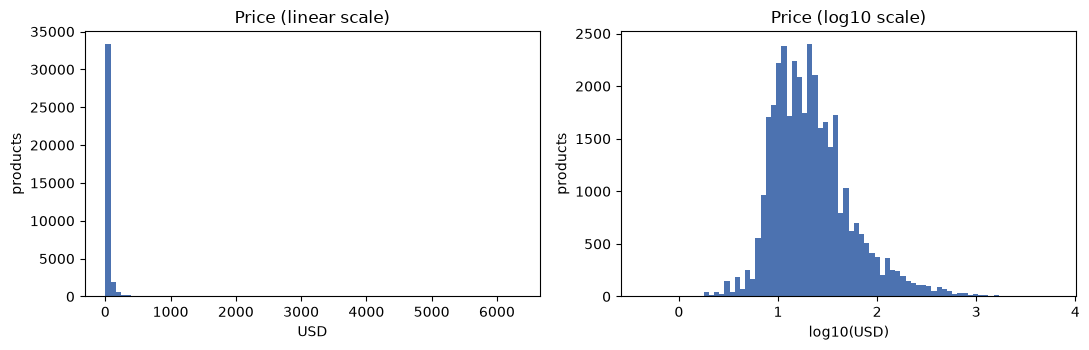

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(p, bins=80, color="#4C72B0")
axes[0].set_title("Price (linear scale)")
axes[0].set_xlabel("USD")
axes[1].hist(np.log10(p), bins=80, color="#4C72B0")
axes[1].set_title("Price (log10 scale)")
axes[1].set_xlabel("log10(USD)")
for ax in axes:
    ax.set_ylabel("products")
plt.tight_layout()
plt.savefig(FIG / "fig02_price_outliers.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

در جدول بالا، بیشتر محصولات گران واقعاً محصولات کنترلی گران‌قیمت‌اند (مثل پهپاد DJI Inspire)، ولی **یک ترازوی دقیق** هم در میانشان هست. یعنی درخت دسته‌بندی آمازون گاهی محصولی را اشتباه در این شاخه گذاشته است؛ همان مشکلی که در نوت‌بوک ۱ با کابل HDMI دیدیم.

در مقیاس خطی تقریباً همه‌ی محصولات در یک ستون کنار صفر جمع شده‌اند و چند محصول گران همه‌ی نمودار را کش داده‌اند. در **مقیاس لگاریتمی** توزیع خوانا می‌شود. نتیجه: قیمت را در فاز ۲ با لگاریتم وارد می‌کنیم، نه با حذف پرت‌ها.

### ۵-۴. کاربران پرنقد

</div>

In [12]:
per_user = reviews.groupby("user_id").agg(
    reviews=("rating", "size"),
    mean_rating=("rating", "mean"),
    verified_share=("verified_purchase", "mean"),
    median_text_len=("text_len", "median"),
    first=("timestamp", "min"),
    last=("timestamp", "max"),
)
for c in ("first", "last"):
    per_user[c] = pd.to_datetime(per_user[c], unit="ms").dt.year

overall = pd.DataFrame({
    "reviews": [1], "mean_rating": [reviews["rating"].mean()],
    "verified_share": [reviews["verified_purchase"].mean()],
    "median_text_len": [text_len.median()], "first": [None], "last": [None],
}, index=["(all reviewers)"])

pd.concat([per_user.nlargest(10, "reviews"), overall]).round(2)

,reviews,mean_rating,verified_share,median_text_len,first,last
AHRGF6F3V3NEUNMWWV7XP4ZNQEEA,200,3.88,0.48,310.5,2013,2023
AEXBCZFVZ72RRPDFB374HGTVDU5A,178,4.70,0.44,46.0,2017,2023
AEZDOY3YR2MX6DW7NFP7OHN6C2DQ,175,3.80,0.44,499.0,2019,2023
AFTREIKPCTDVX3VHAJBSQHO3LLQA,162,3.78,1.00,20.0,2016,2018
AFIW3PMU7FJEYVAZU3EKUAO3G66A,145,4.75,0.96,278.0,2017,2023
AHTDYGXHONM2BHENDRMKMC34ZZZA,123,4.51,0.93,690.0,2015,2022
AFEAPSOCIKU4EPSKQNBOEEUUJXLA,117,3.38,0.96,117.0,2016,2022
AE7V2EJC3FWCFANCFD2JT3F7WG5A,116,4.29,0.90,125.5,2017,2023
AHVHPO45ZEPNRSHYZXECSIAMSDIA,115,4.64,1.00,106.0,2019,2023
AET4Q3AB6WZMHRPN2ZQK4AVQJYRA,111,4.80,1.00,4.0,2015,2016


<div dir="rtl">

اگر کاربران پرنقد **اسپم** بودند، انتظار داشتیم همه‌ی نقدهایشان ۵ ستاره، کوتاه و در یک بازه‌ی زمانی کوتاه باشد. جدول بالا را با این انتظار مقایسه کنید: بیشتر کاربران پرنقد امتیازهای متنوع و متن‌های بلند در چند سال دارند (شبیه علاقه‌مندان جدی)، ولی چند نفر الگوی مشکوک دارند: متن‌های چند کاراکتری، امتیاز بالا و فعالیت در بازه‌ای کوتاه.

</div>

<div dir="rtl">

## ۶. جدول تصمیم‌ها

برای هر مشکل: چقدر است، چه تصمیمی گرفتیم و چرا. این جدول در گزارش فاز ۱ می‌آید.

</div>

In [13]:
d_level = (reviews.duplicated(["user_id", "text"])
           & ~reviews.duplicated(["user_id", "parent_asin", "text"])).sum()
e_level = reviews[long_text].duplicated("text").sum()

decisions = pd.DataFrame([
    ("Exact duplicate reviews (level A/B)", dup.iloc[0],
     "drop (keep first copy)",
     "same user, product and second: a collection error, not a second opinion"),
    ("Same user + product, different time (level C)", dup.iloc[2] - dup.iloc[1],
     "keep, flag",
     "can be a genuine update after using the product longer"),
    ("Same user + text on another product (level D)", d_level,
     "keep, flag; revisit in phase 2",
     "may be one review shown on sister listings; would double-count text when learning aspects"),
    ("Same long text from different users (level E)", e_level,
     "keep, flag; inspect in phase 2",
     "may be templates or spam; too early to delete without reading them"),
    ("Empty review text", (text_len == 0).sum(),
     "keep for rating analysis; no text features",
     "the star rating is still valid information"),
    ("Very short text (1-20 chars)", text_len.between(1, 20).sum(),
     "keep",
     "'Great!' is a real opinion; it simply carries no aspect information"),
    ("Reviews with markup in text (HTML, video codes)", int(any_markup),
     "clean in phase 2 preprocessing",
     "markup is not customer language and would confuse text models"),
    ("Impossible values (rating, time, price)", int(impossible.sum()),
     "none found; no action", "all values inside valid ranges"),
    ("Price missing", meta["price"].isna().sum(),
     "keep; study in task 6",
     "need to know if missingness is random before choosing how to handle it"),
    ("Price outliers (> $1000)", (meta["price"] > 1000).sum(),
     "keep; use log(price); flag miscategorised items",
     "mostly real high-end products (e.g. DJI Inspire drones); a few are miscategorised (e.g. a weighing scale)"),
    ("helpful_vote outliers", (reviews["helpful_vote"] > reviews["helpful_vote"].quantile(.999)).sum(),
     "keep; never a model feature",
     "real but collected after the review was written (leakage)"),
    ("Heavy reviewers (>= 50 reviews)", int((per_user["reviews"] >= 50).sum()),
     "keep, flag; inspect suspicious ones in phase 2",
     "most look like enthusiasts (mixed ratings, long texts, many years); a few look suspicious (very short texts, high ratings, short active period)"),
], columns=["issue", "count", "decision", "reason"])

decisions.to_csv(REP / "quality_decisions.csv", index=False)
decisions

,issue,count,decision,reason
0,Exact duplicate reviews (level A/B),10695,drop (keep first copy),"same user, product and second: a collection error, not a second opinion"
1,"Same user + product, different time (level C)",1378,"keep, flag",can be a genuine update after using the product longer
2,Same user + text on another product (level D),15579,"keep, flag; revisit in phase 2",may be one review shown on sister listings; would double-count text when learning aspects
3,Same long text from different users (level E),10360,"keep, flag; inspect in phase 2",may be templates or spam; too early to delete without reading them
4,Empty review text,1226,keep for rating analysis; no text features,the star rating is still valid information
5,Very short text (1-20 chars),92833,keep,'Great!' is a real opinion; it simply carries no aspect information
6,"Reviews with markup in text (HTML, video codes)",112254,clean in phase 2 preprocessing,markup is not customer language and would confuse text models
7,"Impossible values (rating, time, price)",0,none found; no action,all values inside valid ranges
8,Price missing,34313,keep; study in task 6,need to know if missingness is random before choosing how to handle it
9,Price outliers (> $1000),74,keep; use log(price); flag miscategorised items,mostly real high-end products (e.g. DJI Inspire drones); a few are miscategorised (e.g. a weighi...


<div dir="rtl">

## ۷. جمع‌بندی

**وضعیت کلی:** داده‌ی زیرمجموعه از نظر ستون‌های اصلی سالم است. امتیاز، زمان و شناسه‌ی محصول برای همه‌ی ۸۶۲ هزار نقد کامل‌اند و هیچ مقدار ناممکنی (امتیاز بیرون از ۱ تا ۵، زمان پس از جمع‌آوری، قیمت صفر یا منفی) پیدا نشد.

**گمشدگی**
- تنها ۰٫۱۴٪ نقدها متن خالی دارند. مهم‌ترین گمشدگی، قیمت است (۴۸٪ محصولات) که در تسک ۶ بررسی می‌شود.
- نبود تصویر در ۹۲٪ نقدها و ویدیو در ۷۲٪ محصولات گمشدگی نیست؛ یعنی این وجه‌ها برای بیشتر نمونه‌ها وجود ندارند.
- `bought_together` در هیچ محصولی مقدار ندارد و کنار گذاشته می‌شود.

**تکرار**
- ۱۰٬۶۹۵ نقد (۱٫۲۴٪) کاملاً تکراری‌اند (همان کاربر، همان محصول، همان ثانیه) و در فاز ۲ حذف می‌شوند.
- ۱۵٬۵۷۹ نقد متن یکسانی از یک کاربر روی محصولات مختلف دارند (مثلاً «Perfect! I am incredibly glad to get this.» روی سه محصول)، و ۱۰٬۳۶۰ نقد بلند متنی دارند که کاربر دیگری هم عیناً نوشته است. این‌ها علامت‌گذاری می‌شوند و در فاز ۲ بررسی می‌شوند، چون در یادگیری جنبه‌ها یک متن را چند بار حساب می‌کنند.

**امتیاز:** توزیع J شکل است: ۶۳٫۶٪ پنج ستاره، ۱۳٫۶٪ یک ستاره و سهم کم امتیازهای میانی. این سوگیری خودگزینی را تأیید می‌کند و در انتخاب معیار ارزیابی مدل (تسک ۱۲) مهم است.

**کیفیت متن**
- ۱۳٪ نقدها نشانه‌گذاری فنی دارند (عمدتاً تگ `<br />` و کد ویدیو) که در پیش‌پردازش فاز ۲ پاک می‌شود.
- حدود ۱۱٪ نقدها ۲۰ کاراکتر یا کمترند (مثل «Good» و «Works great»). نگه داشته می‌شوند چون نظر واقعی‌اند، ولی اطلاعاتی درباره‌ی جنبه‌ها ندارند.

**پرت‌ها**
- **قیمت:** میانه ۱۹ دلار و بیشینه ۶٬۳۴۶ دلار. بیشتر محصولات گران واقعی‌اند (پهپاد DJI Inspire)، ولی یک ترازوی آزمایشگاهی هم در زیرمجموعه است؛ نشانه‌ی دیگری از خطای برچسب درخت دسته‌بندی. قیمت در فاز ۲ با لگاریتم وارد می‌شود.
- **رأی مفید:** میانه ۰ و بیشینه ۳٬۰۲۴. واقعی است ولی به‌دلیل نشت اطلاعات هرگز ویژگی مدل نمی‌شود.
- **کاربران پرنقد:** ۱۲۱ کاربر دست‌کم ۵۰ نقد دارند. بیشترشان شبیه علاقه‌مندان جدی‌اند، ولی چند نفر الگوی مشکوک دارند (مثلاً ۱۱۱ نقد با میانه‌ی طول ۴ کاراکتر، همه در دو سال). علامت‌گذاری و در فاز ۲ بررسی می‌شوند.

جدول کامل تصمیم‌ها در `reports/phase1/quality_decisions.csv` ذخیره شده است.

</div>